Lecture des fichiers csv foourinis

In [12]:
import pandas as pd

# Charger le fichier CSV dans un DataFrame
df1 = pd.read_csv('../data/winequality-red.csv', sep=';')
df2 = pd.read_csv('../data/winequality-white.csv', sep=';')
# Afficher les 5 premières lignes
print(df1.head())
print(df2.head())

   fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
0            7.4              0.70         0.00             1.9      0.076   
1            7.8              0.88         0.00             2.6      0.098   
2            7.8              0.76         0.04             2.3      0.092   
3           11.2              0.28         0.56             1.9      0.075   
4            7.4              0.70         0.00             1.9      0.076   

   free sulfur dioxide  total sulfur dioxide  density    pH  sulphates  \
0                 11.0                  34.0   0.9978  3.51       0.56   
1                 25.0                  67.0   0.9968  3.20       0.68   
2                 15.0                  54.0   0.9970  3.26       0.65   
3                 17.0                  60.0   0.9980  3.16       0.58   
4                 11.0                  34.0   0.9978  3.51       0.56   

   alcohol  quality  
0      9.4        5  
1      9.8        5  
2      9.8        5 

In [13]:
df1["Type"] = "red"
df2["Type"] = "white"


Ajout d'un colone type puis fusion des 2 datasets

In [14]:
# 2. Concaténer les DataFrames verticalement
df_combine = pd.concat([df1, df2], ignore_index=True)

# 3. Sauvegarder dans un nouveau fichier CSV
df_combine.to_csv('../data/winequality.csv', index=False)

In [16]:
df = pd.read_csv('../data/winequality.csv', sep=',')
df.shape 
df.head() 
df.info() 
df.describe()

<class 'pandas.DataFrame'>
RangeIndex: 6497 entries, 0 to 6496
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         6497 non-null   float64
 1   volatile acidity      6497 non-null   float64
 2   citric acid           6497 non-null   float64
 3   residual sugar        6497 non-null   float64
 4   chlorides             6497 non-null   float64
 5   free sulfur dioxide   6497 non-null   float64
 6   total sulfur dioxide  6497 non-null   float64
 7   density               6497 non-null   float64
 8   pH                    6497 non-null   float64
 9   sulphates             6497 non-null   float64
 10  alcohol               6497 non-null   float64
 11  quality               6497 non-null   int64  
 12  Type                  6497 non-null   str    
dtypes: float64(11), int64(1), str(1)
memory usage: 660.0 KB


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000
mean,7.215307,0.339666,0.318633,5.443235,0.056034,30.525319,115.744574,0.994697,3.218501,0.531268,10.491801,5.818378
std,1.296434,0.164636,0.145318,4.757804,0.035034,17.749400,56.521855,0.002999,0.160787,0.148806,1.192712,0.873255
min,3.800000,0.080000,0.000000,0.600000,0.009000,1.000000,6.000000,0.987110,2.720000,0.220000,8.000000,3.000000
25%,6.400000,0.230000,0.250000,1.800000,0.038000,17.000000,77.000000,0.992340,3.110000,0.430000,9.500000,5.000000
50%,7.000000,0.290000,0.310000,3.000000,0.047000,29.000000,118.000000,0.994890,3.210000,0.510000,10.300000,6.000000
75%,7.700000,0.400000,0.390000,8.100000,0.065000,41.000000,156.000000,0.996990,3.320000,0.600000,11.300000,6.000000
max,15.900000,1.580000,1.660000,65.800000,0.611000,289.000000,440.000000,1.038980,4.010000,2.000000,14.900000,9.000000


Detection des duplicats et supressions

In [20]:
print(df.duplicated().sum())

0


In [21]:
df = df.drop_duplicates()
df.shape

(5320, 13)

Valeurs abhérantes

In [23]:
# Les 11 variables physico-chimiques (on exclut Type = texte, et quality = la cible)
cols = df.select_dtypes("number").columns.drop("quality")

resultats = []
for col in cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1                        # écart interquartile
    borne_basse = q1 - 1.5 * iqr
    borne_haute = q3 + 1.5 * iqr

    # True pour chaque valeur hors des bornes, puis on compte les True
    est_outlier = (df[col] < borne_basse) | (df[col] > borne_haute)
    n_outliers = est_outlier.sum()
    pct = 100 * n_outliers / len(df)

    resultats.append({"variable": col, "n_outliers": n_outliers, "pourcentage": round(pct, 2)})

# Un tableau trié du plus touché au moins touché
outliers = pd.DataFrame(resultats).sort_values("pourcentage", ascending=False)
outliers

,variable,n_outliers,pourcentage
0,fixed acidity,304,5.71
1,volatile acidity,279,5.24
4,chlorides,237,4.45
9,sulphates,163,3.06
2,citric acid,143,2.69
3,residual sugar,141,2.65
8,pH,49,0.92
5,free sulfur dioxide,44,0.83
6,total sulfur dioxide,10,0.19
7,density,3,0.06


In [24]:
au_moins_un = pd.Series(False, index=df.index)   # au départ, aucune ligne n'est marquée

for col in cols:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    est_outlier = (df[col] < q1 - 1.5 * iqr) | (df[col] > q3 + 1.5 * iqr)
    au_moins_un = au_moins_un | est_outlier       # une ligne reste marquée dès qu'elle a été outlier une fois

n = au_moins_un.sum()
print(f"{n} lignes ont au moins un outlier, soit {100 * n / len(df):.1f} % des données")

1094 lignes ont au moins un outlier, soit 20.6 % des données


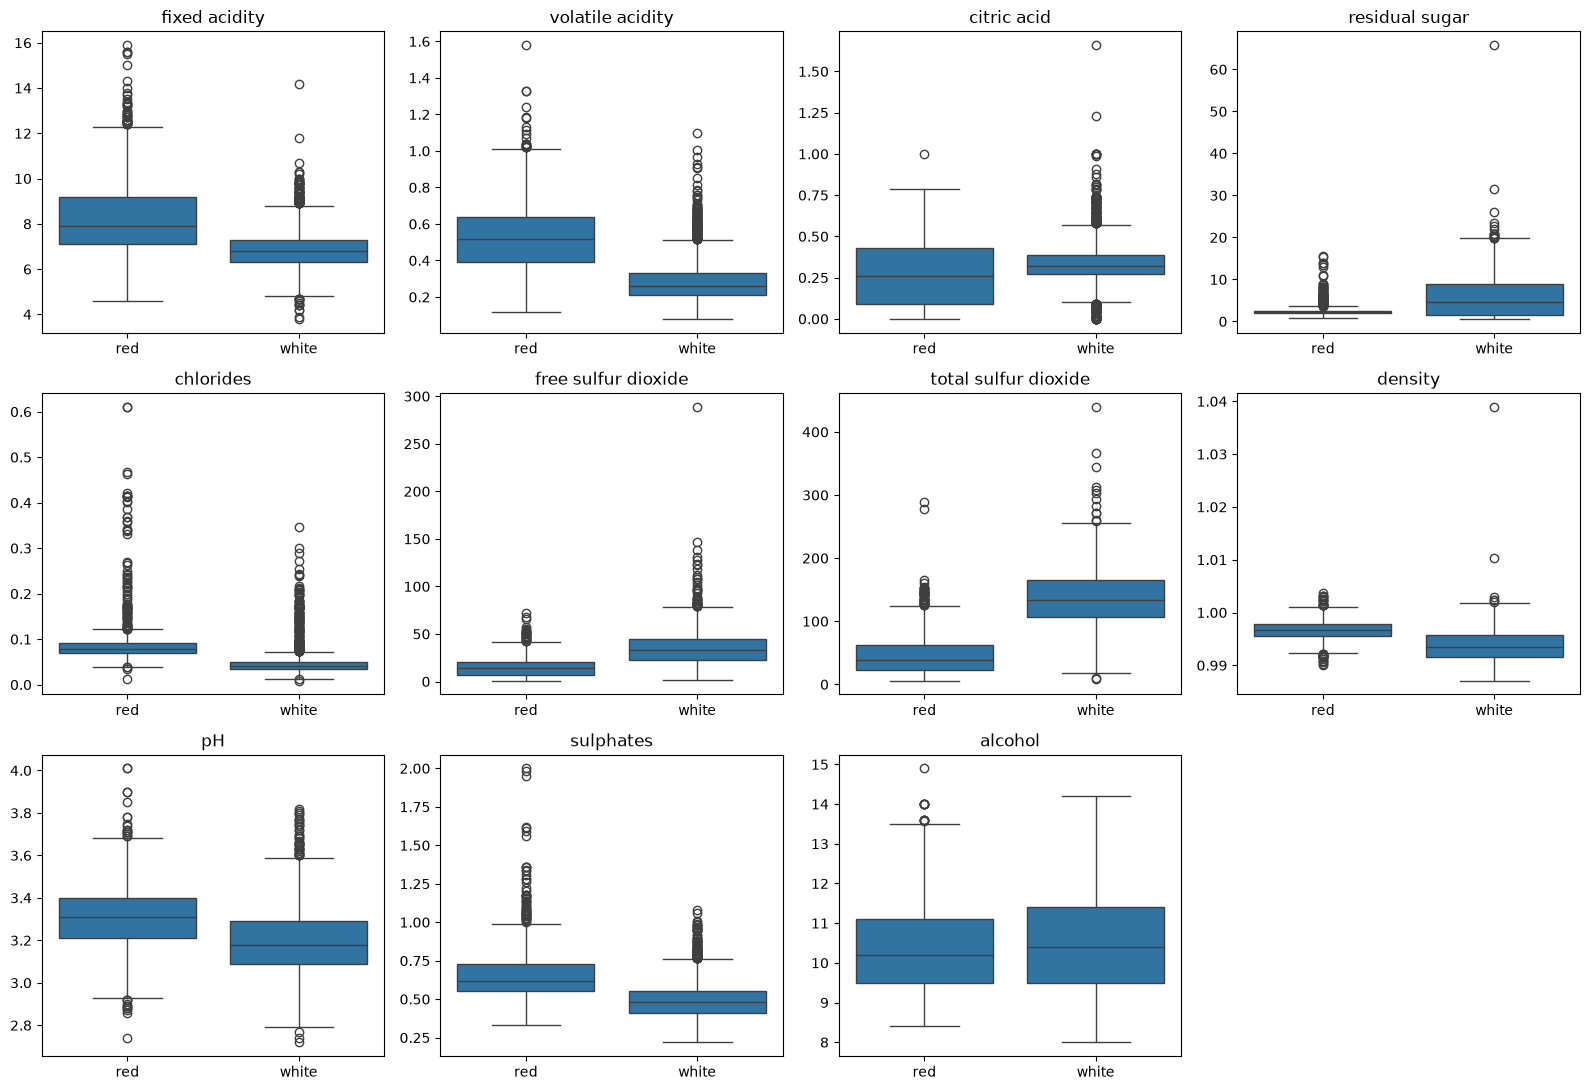

In [25]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(3, 4, figsize=(16, 11))   # grille de 12 cases pour 11 variables
for ax, col in zip(axes.flat, cols):
    sns.boxplot(data=df, x="Type", y=col, ax=ax)
    ax.set_title(col)
    ax.set_xlabel("")
    ax.set_ylabel("")
axes.flat[-1].axis("off")                           # on masque la 12e case, vide
plt.tight_layout()
plt.show()

In [26]:
def compter_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()

comparaison = pd.DataFrame({
    "bornes globales": [compter_outliers(df[c]) for c in cols],
    "bornes par type": [df.groupby("Type")[c].apply(compter_outliers).sum() for c in cols],
}, index=cols)
comparaison

,bornes globales,bornes par type
fixed acidity,304,147
volatile acidity,279,152
citric acid,143,224
residual sugar,141,142
chlorides,237,265
free sulfur dioxide,44,70
total sulfur dioxide,10,59
density,3,41
pH,49,74
sulphates,163,151
